# God's number for $\mathrm{SL}_2(\mathbb{Z}/p\mathbb{Z})$ — project notebook

**Project:** *AI powered experiments on* $\mathrm{SL}_2(\mathbb{Z}_p)$ (proposal of 25 January 2026).
**Authors of the proposal:** Benjamin Krawciw, Jake Quinn, Cody Strouse, Steph Tilneac, Wenzhuo Wu.
**This notebook:** October 2026. It gathers everything in the repository — the proposal, the
mathematics behind it (with definitions and proofs spelled out), the code that computes exact
diameters, the data produced so far, and the questions that remain open.

Every number quoted in the prose below is recomputed by a code cell, so the text and the data
cannot drift apart. Cells that need the pre-computed tables read them from `data/`; the commands
that produced those tables are in the appendix.

**How to read this notebook.** Sections 1–4 are self-contained background (what the group is,
what the generators are, what "God's number" means, what is known). Section 5 explains the
algorithm. Sections 6–10 are results, each looking at the same data from a different angle.
Section 11 re-examines the proposal's goals in the light of the results and lists open questions.

In [1]:
import json, math, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

# locate the repository root (the directory that contains the ``godsnumber`` package)
ROOT = Path.cwd()
while not (ROOT / "godsnumber").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from godsnumber import (S, T, U, bfs, bfs_reference, counting_lower_bound, decode, decode_scalar,
                        det, encode, encode_scalar, generators, group_order, identity, inverse,
                        inverse_table, mat_pow, matmul, order, reduce_mod)
from godsnumber.integer_growth import (entry_bound, growth_lower_bound, injective_radius,
                                       layers_extended, sl2z_layers)
from godsnumber.spectral import spectrum

pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 160)

# --- plotting conventions -------------------------------------------------------------
# Two categorical series throughout: the directed convention is blue, the undirected one is
# orange, in every figure.  Several values of p (an ordered quantity) use one blue ramp.
PAL = {"directed": "#2a78d6", "undirected": "#eb6834"}
SEQ = ["#86b6ef", "#6da7ec", "#5598e7", "#3987e5", "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
matplotlib.rcParams.update({"font.family": "sans-serif", "font.size": 10, "figure.dpi": 110,
                            "legend.frameon": False, "legend.fontsize": 9})

def style(ax, title=None, xlabel=None, ylabel=None):
    ax.set_facecolor(SURFACE); ax.figure.set_facecolor(SURFACE)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(AXIS)
    ax.tick_params(colors=MUTED, labelcolor=INK2, length=3)
    ax.grid(True, color=GRID, linewidth=0.75)
    ax.set_axisbelow(True)
    if title: ax.set_title(title, color=INK, loc="left", fontsize=11, pad=10)
    if xlabel: ax.set_xlabel(xlabel, color=INK2)
    if ylabel: ax.set_ylabel(ylabel, color=INK2)

LINE = dict(lw=1.5, solid_capstyle="round", solid_joinstyle="round")
DOT = dict(ms=6, markeredgecolor=SURFACE, markeredgewidth=1.2)
print("repository root:", ROOT)

repository root: /home/user/God-s-Number-Project


## 1. The proposal (January 2026) and the state of the project

The repository originally contained only the proposal (`proposal/prop.tex`, two pages) and its
outline. No code or data existed. The proposal, condensed:

> We propose using AI assisted programming to explore the diameter of the group
> $\mathrm{SL}_2(\mathbb{Z}_p)$. [...] $\mathrm{SL}_2(\mathbb{Z}_p)$ has two generators, $S$ and $T$.
> Given any $\gamma$ we can consider how many applications of $S$ and $T$ are needed to reach it.
> There is a smallest such number, call it $\ell(\gamma)$ [...] the largest $\ell(\gamma)$ is known as the
> diameter of the group, or informally, God's number. [...] It is known that
> $G(\mathrm{SL}_2(\mathbb{Z}_p)) = O(\log p)$, but the asymptotic constant $C$ is not known.

**Basic goals** (quoted): (1) a robust class for $\mathrm{SL}(2,\mathbb{Z}/p\mathbb{Z})$ arithmetic;
(2) a breadth-first search computing the exact Cayley graph and God's number for small primes,
"up to maybe $p \approx 100$"; (3) a table of pairs $(p, G(p))$ and a plot of $G(p)$ against $\log p$;
(4) a least-squares estimate of $C$ in $G(p) \approx C \log p$.

**Reach goals** (quoted): (1) a reinforcement-learning solver finding short paths for $p > 500$
"where BFS is computationally intractable"; (2) using solver lengths as a "practical" diameter;
(3) the distribution of path lengths as $p \to \infty$; (4) how the constant $C$ depends on the generating set.

**References in the proposal:** Helfgott, *Growth and generation in* $\mathrm{SL}_2(\mathbb{Z}/p\mathbb{Z})$,
Ann. of Math. 167 (2008) (arXiv math/0509024); Lubotzky–Phillips–Sarnak, *Ramanujan graphs*,
Combinatorica 8 (1988); Chervov et al., *CayleyPy RL*, arXiv:2502.18663 (2025).

**Status after this notebook.** All four basic goals are done, and well beyond the proposed range:
exact diameters are tabulated for every prime up to 500 and for a few primes near 1000, in both of
the two possible conventions (Section 3 explains why there are two). Reach goal (3) is partly done
(Section 8), reach goal (4) is started (Section 11), and reach goals (1)–(2) are re-assessed in
Section 11: BFS is *not* intractable at $p > 500$, and a solver's lengths do not bound the diameter.

## 2. The group $\mathrm{SL}_2(\mathbb{Z}/p\mathbb{Z})$

Throughout, $p$ is a prime and $\mathbb{F}_p = \mathbb{Z}/p\mathbb{Z}$ is the field with $p$ elements:
the integers modulo $p$, where every nonzero element has a multiplicative inverse because $p$ is prime.

**Definition.** $\mathrm{SL}_2(\mathbb{F}_p)$ is the set of $2\times 2$ matrices
$\begin{pmatrix} a & b\\ c & d\end{pmatrix}$ with $a,b,c,d \in \mathbb{F}_p$ and $ad - bc = 1$.
It is a group under matrix multiplication: the determinant is multiplicative, so a product of two
determinant-one matrices has determinant one, and the inverse of $\begin{pmatrix} a & b\\ c & d\end{pmatrix}$
is $\begin{pmatrix} d & -b\\ -c & a\end{pmatrix}$, which again has determinant $ad - bc = 1$.

**Order.** $|\mathrm{SL}_2(\mathbb{F}_p)| = p(p^2-1) = p^3 - p$.

*Proof.* Choose the first row $(a, b)$: it must be nonzero (otherwise the determinant is $0$), which
leaves $p^2 - 1$ choices. For a fixed nonzero $(a,b)$ the map $(c, d) \mapsto ad - bc$ is a
nonzero linear functional on $\mathbb{F}_p^2$, so it is onto $\mathbb{F}_p$ and each of its $p$ values is taken
by exactly $p$ pairs $(c,d)$. The value $1$ is therefore taken $p$ times, giving $(p^2-1)\,p$ matrices. $\square$

**Two notational warnings** (both affect the proposal's wording).

* $\mathbb{Z}_p$ usually denotes the $p$-adic integers, an infinite ring. The finite group studied
  here is $\mathrm{SL}_2(\mathbb{Z}/p\mathbb{Z}) = \mathrm{SL}_2(\mathbb{F}_p)$. We write $\mathbb{F}_p$ from now on.
* $\mathrm{SL}_2(\mathbb{Z})$, the integer matrices of determinant one, is an infinite group. Its Cayley graph
  has infinite diameter, so "God's number of $\mathrm{SL}_2(\mathbb{Z})$" is not a meaningful quantity; what
  is meaningful is the number for each finite quotient $\mathrm{SL}_2(\mathbb{F}_p)$, and how it grows with $p$.
  $\mathrm{SL}_2(\mathbb{Z})$ will nevertheless play a central role in Section 7.

In [2]:
import itertools

def all_elements(p):
    "Every determinant-one matrix over F_p, by brute force (fine for p <= 13)."
    return [m for m in itertools.product(range(p), repeat=4) if det(m, p) == 1 % p]

for p in [2, 3, 5, 7, 11]:
    assert len(all_elements(p)) == group_order(p)
    print(f"p = {p:2d}: |SL_2(F_p)| = {group_order(p):5d} = {p}^3 - {p}")

p =  2: |SL_2(F_p)| =     6 = 2^3 - 2
p =  3: |SL_2(F_p)| =    24 = 3^3 - 3
p =  5: |SL_2(F_p)| =   120 = 5^3 - 5
p =  7: |SL_2(F_p)| =   336 = 7^3 - 7
p = 11: |SL_2(F_p)| =  1320 = 11^3 - 11


## 3. The generators $S$ and $T$, and the two conventions

$$
S = \begin{pmatrix} 0 & -1 \\ 1 & 0 \end{pmatrix}, \qquad
T = \begin{pmatrix} 1 & 1 \\ 0 & 1 \end{pmatrix}, \qquad
U = S T^{-1} S^{-1} = \begin{pmatrix} 1 & 0 \\ 1 & 1 \end{pmatrix}.
$$

These are integer matrices; reducing their entries modulo $p$ gives elements of $\mathrm{SL}_2(\mathbb{F}_p)$
that we denote by the same letters. The basic relations, checked below, are
$$ S^2 = -I,\quad S^4 = I,\qquad T^k = \begin{pmatrix} 1 & k\\ 0 & 1\end{pmatrix},\quad T^p = I \text{ in } \mathrm{SL}_2(\mathbb{F}_p),\qquad (ST)^3 = -I. $$

**Why $S$ and $T$ generate $\mathrm{SL}_2(\mathbb{F}_p)$.** It is enough to show that $T$ and $U$ do, since
$U = ST^{-1}S^{-1}$. Let $M = \begin{pmatrix} a & b\\ c & d\end{pmatrix} \in \mathrm{SL}_2(\mathbb{F}_p)$.

* If $c \neq 0$: left-multiplying by $T^{x}$ with $x = (1-a)/c$ makes the top-left entry
  $a + xc = 1$. With $a = 1$, left-multiplying by $U^{-c}$ gives
  $\begin{pmatrix} 1 & b\\ 0 & d - cb\end{pmatrix}$, and $d - cb = ad - bc = 1$, so the result is
  $T^{b}$. Unwinding, $M = U^{c}\, T^{-x}\, T^{b}$ is a product of powers of $T$ and $U$.
* If $c = 0$: then $ad = 1$ so $a \neq 0$; left-multiplying by $U$ gives a matrix with
  bottom-left entry $a \neq 0$, and the first case applies.

So $\langle T, U\rangle = \mathrm{SL}_2(\mathbb{F}_p)$, hence $\langle S, T\rangle = \mathrm{SL}_2(\mathbb{F}_p)$. $\square$
(The same argument with Euclid's algorithm in place of division shows that $S, T$ generate $\mathrm{SL}_2(\mathbb{Z})$.)

**The two conventions.** The proposal counts "applications of $S$ and $T$" and describes the Cayley
graph as *directed*. That is one legitimate convention, but most of the literature (Helfgott
included) uses the *undirected* one. The two give different numbers, so both are computed here:

| name | generating set | Cayley graph | word of length $n$ |
|---|---|---|---|
| **directed** | $\{S, T\}$ | out-degree 2, directed edges $x \to xS$, $x \to xT$ | $g_1 g_2 \cdots g_n$ with $g_i \in \{S, T\}$ |
| **undirected** | $\{S, S^{-1}, T, T^{-1}\}$ | 4-regular, undirected (for odd $p$) | $g_i \in \{S^{\pm 1}, T^{\pm 1}\}$ |

In a finite group every inverse is a positive power ($S^{-1} = S^3$, $T^{-1} = T^{p-1}$), so $\{S, T\}$
generates the group even without inverses — the directed graph is strongly connected. For $p = 2$
one has $S = S^{-1}$ and $T = T^{-1}$ and the two conventions coincide.

In [3]:
for p in [5, 7, 11, 13]:
    s, t = reduce_mod(S, p), reduce_mod(T, p)
    assert mat_pow(s, 2, p) == reduce_mod((-1, 0, 0, -1), p)        # S^2 = -I
    assert order(s, p) == 4 and order(t, p) == p                      # S^4 = I, T^p = I
    assert mat_pow(matmul(s, t, p), 3, p) == reduce_mod((-1, 0, 0, -1), p)   # (ST)^3 = -I
    assert matmul(matmul(s, inverse(t, p), p), inverse(s, p), p) == reduce_mod(U, p)  # S T^-1 S^-1 = U
    print(f"p = {p:2d}: relations verified;  generators (directed) = {generators(p, 'directed')}")
print("undirected generating set for p = 7:", generators(7, "undirected"))
print("for p = 2 the two sets coincide:", generators(2, "directed"), generators(2, "undirected"))

p =  5: relations verified;  generators (directed) = [(0, 4, 1, 0), (1, 1, 0, 1)]
p =  7: relations verified;  generators (directed) = [(0, 6, 1, 0), (1, 1, 0, 1)]
p = 11: relations verified;  generators (directed) = [(0, 10, 1, 0), (1, 1, 0, 1)]
p = 13: relations verified;  generators (directed) = [(0, 12, 1, 0), (1, 1, 0, 1)]
undirected generating set for p = 7: [(0, 6, 1, 0), (1, 1, 0, 1), (0, 1, 6, 0), (1, 6, 0, 1)]
for p = 2 the two sets coincide: [(0, 1, 1, 0), (1, 1, 0, 1)] [(0, 1, 1, 0), (1, 1, 0, 1)]


## 4. Word length, the Cayley graph, and "God's number"

Fix $p$ and one of the two generating sets $A$. For $\gamma \in \mathrm{SL}_2(\mathbb{F}_p)$ the **word length** is
$$ \ell(\gamma) = \min\{\, n \ge 0 : \gamma = g_1 g_2 \cdots g_n \text{ with all } g_i \in A \,\}, $$
with $\ell(I) = 0$. The **Cayley graph** $\mathrm{Cay}(G, A)$ has the group elements as vertices and an edge
from $x$ to $xg$ for each $g \in A$. Then $\ell(\gamma)$ is the graph distance from $I$ to $\gamma$.

**God's number** is $G(p) = \max_\gamma \ell(\gamma)$. The name comes from Rubik's cube: the cube
positions form a group, the face turns are a generating set, and "God's number" (20 for half-turns
counting as one move, 26 for quarter turns) is the largest number of moves any position needs. The
two cube metrics are exactly analogous to the two conventions above: they differ in which moves count as one step.

**$G(p)$ is the diameter, and also the radius, of the Cayley graph.** For any $h \in G$, left
multiplication $L_h : x \mapsto hx$ maps the edge $x \to xg$ to the edge $hx \to hxg$, so $L_h$ is a
graph automorphism taking $I$ to $h$. Hence every vertex has the same eccentricity (largest distance
to another vertex), and that common value is $\max_\gamma \ell(\gamma) = G(p)$. The diameter (largest
eccentricity) and radius (smallest eccentricity) therefore coincide. This justifies the proposal's
sentence "by computing $G$ we are finding the radius of these graphs" — radius and diameter are the same thing here.

**In the undirected convention $\ell(\gamma^{-1}) = \ell(\gamma)$:** if $\gamma = g_1 \cdots g_n$ then
$\gamma^{-1} = g_n^{-1} \cdots g_1^{-1}$ is also a word of length $n$ in $A$, since $A$ is closed under
inverses. In the directed convention this can fail.

**Left or right multiplication does not matter for $\ell$.** Whether one builds words by appending
generators on the right ($x \mapsto xg$) or on the left ($x \mapsto gx$), the set of products of
exactly $n$ generators is the same set, so the layers $\{\gamma : \ell(\gamma) = n\}$ and all the numbers
in this notebook are identical. (The two graphs are different as labelled graphs, but isomorphic.)

The smallest cases, by a dictionary-based breadth-first search (the reference implementation):

In [4]:
for p in [2, 3, 5]:
    for conv in ["directed", "undirected"]:
        r = bfs_reference(p, conv)
        print(f"p = {p}  {conv:10s}  |L_0|, |L_1|, ... = {r.layer_sizes}   God's number = {r.diameter}")
print()
print("p = 2: SL_2(F_2) is the symmetric group S_3; S and T are two transpositions, the Cayley graph")
print("       is a hexagon and God's number is 3.  The layer sizes 1, 2, 2, 1 are the hexagon seen from a vertex.")

p = 2  directed    |L_0|, |L_1|, ... = [1, 2, 2, 1]   God's number = 3
p = 2  undirected  |L_0|, |L_1|, ... = [1, 2, 2, 1]   God's number = 3
p = 3  directed    |L_0|, |L_1|, ... = [1, 2, 4, 6, 6, 5]   God's number = 5
p = 3  undirected  |L_0|, |L_1|, ... = [1, 4, 9, 10]   God's number = 3
p = 5  directed    |L_0|, |L_1|, ... = [1, 2, 4, 7, 11, 14, 18, 18, 21, 15, 9]   God's number = 10
p = 5  undirected  |L_0|, |L_1|, ... = [1, 4, 11, 18, 22, 20, 20, 16, 6, 2]   God's number = 9

p = 2: SL_2(F_2) is the symmetric group S_3; S and T are two transpositions, the Cayley graph
       is a hexagon and God's number is 3.  The layer sizes 1, 2, 2, 1 are the hexagon seen from a vertex.


## 5. What is known — and what the proposal misstated

### 5.1 Helfgott's theorem (2008)

Helfgott proved, for $G = \mathrm{SL}_2(\mathbb{F}_p)$ and **any** generating set $A$ (not just $S,T$):
either $A \cdot A \cdot A = G$, or $|A\cdot A\cdot A| \ge |A|^{1+\varepsilon}$ for an absolute constant
$\varepsilon > 0$ (slightly simplified; the exact statement has a size threshold). Products of a set with
itself therefore grow until they fill the group, and iterating $O(\log\log p)$ times gives
$$ \operatorname{diam}\mathrm{Cay}(G, A) \le C (\log p)^{c} \qquad\text{for absolute constants } C, c, $$
uniformly over all generating sets. This was the first case of **Babai's conjecture** (every Cayley graph
of every non-abelian finite simple group has diameter $\le (\log |G|)^{O(1)}$); it was extended to all
finite simple groups of Lie type of bounded rank by Breuillard–Green–Tao and by Pyber–Szabó (2011/2016).
Helfgott's bound is *polylogarithmic* — it does not by itself give $O(\log p)$.

### 5.2 Where $O(\log p)$ comes from for $S$ and $T$

For the specific generators $S, T$ a stronger statement is classical and predates Helfgott:
the undirected Cayley graphs $\mathrm{Cay}(\mathrm{SL}_2(\mathbb{F}_p), \{S^{\pm1}, T^{\pm1}\})$, $p$ prime, form an
**expander family**. The chain of reasoning is: $S, T$ generate $\mathrm{SL}_2(\mathbb{Z})$; the kernel of reduction
mod $p$ is the principal congruence subgroup $\Gamma(p)$; Selberg's $\tfrac{3}{16}$ theorem (1965) gives a
uniform lower bound for the first Laplace eigenvalue of the surfaces $\Gamma(p)\backslash\mathbb{H}$; and a
comparison theorem (Brooks, Burger) transfers that to a uniform spectral gap for the finite Cayley graphs
(see Lubotzky, *Discrete groups, expanding graphs and invariant measures*, 1994, Ch. 4). A $k$-regular
expander on $N$ vertices has diameter $O(\log N)$, and here $N = p^3 - p$, so $G(p) = O(\log p)$. The
implied constant depends on the size of the spectral gap, which is why "$C$" is not known: nobody has an
effective, sharp value of the gap. Bourgain–Gamburd (2008) later showed expansion for essentially all
generating pairs, using Helfgott's theorem.

### 5.3 These graphs are **not** the Ramanujan graphs of Lubotzky–Phillips–Sarnak

A connected $k$-regular graph is *Ramanujan* if every adjacency eigenvalue $\lambda \ne \pm k$ satisfies
$|\lambda| \le 2\sqrt{k-1}$ — the best possible spectral gap for an infinite family (Alon–Boppana).
The LPS graphs are $(q+1)$-regular Cayley graphs of $\mathrm{PSL}_2(\mathbb{F}_p)$ or $\mathrm{PGL}_2(\mathbb{F}_p)$
whose generators come from the $q+1$ integer quaternions of norm $q$ — a different generating set,
of different size, and the construction is what makes them Ramanujan. Nothing forces the 4-regular
$S,T$ graphs to be Ramanujan, and Section 10 shows numerically that for $p \ge 5$ they are not. The
defensible statement is "expander", not "Ramanujan". (The word "Ramanujan" is also only defined for
undirected graphs, which is one more reason to compute the undirected convention.)

### 5.4 Lower bounds from counting words

Every element must be a product of at most $G(p)$ generators, so $|B_n| \ge p^3 - p$ for $n = G(p)$, where
$B_n$ is the set of elements of length $\le n$ and $|B_n|$ is at most the number of words of length $\le n$.

* **Directed:** there are $2^k$ words of length $k$, so $|B_n| \le 2^{n+1} - 1$ and
  $G_{\mathrm{dir}}(p) \ge \log_2(p^3 - p + 1) - 1 \approx 3\log_2 p = (3/\ln 2)\ln p \approx 4.33 \ln p$.
* **Undirected** ($p$ odd, four distinct generators): a shortest word never contains $gg^{-1}$, so only
  *reduced* words matter, $4\cdot 3^{k-1}$ of length $k \ge 1$; thus $|B_n| \le 2\cdot 3^n - 1$ and
  $G_{\mathrm{undir}}(p) \ge \log_3\!\big((p^3-p+1)/2\big) \approx (3/\ln 3)\ln p \approx 2.73\ln p$.

Any experimental constant must exceed these. Section 7 replaces them with a much stronger bound that uses
the actual growth of $\mathrm{SL}_2(\mathbb{Z})$. Note also that $C$ depends on the base of the logarithm; all
constants in this notebook are for the **natural** logarithm.

### 5.5 A rigorous upper bound that does not need the whole group (the half-ball lemma)

**Lemma.** If $|B_r| > |G|/2$ then $G(p) \le 2r$, in either convention.
*Proof.* Let $g \in G$. The sets $B_r$ and $g\,B_r^{-1}$ (where $B_r^{-1} = \{x^{-1} : x \in B_r\}$) both have
$|B_r| > |G|/2$ elements, so they intersect: $x = g y^{-1}$ for some $x, y \in B_r$, i.e. $g = xy$ with
$\ell(x), \ell(y) \le r$, so $\ell(g) \le 2r$. $\square$

So a BFS that is stopped once half the group is reached already proves $G(p) \le 2r$. This is the
kind of statement the proposal's reach goal (2) was after; by contrast the length of a word found by a
heuristic solver for *some* element bounds $\ell$ of that element only, and says nothing about the maximum.

## 6. Computing $G(p)$ exactly

### 6.1 Numbering the group elements

A breadth-first search must remember which elements it has seen. Instead of a hash set of matrices, every
element gets an index in $\{0, 1, \dots, p^3 - p - 1\}$, so "seen" is one byte array and a whole layer is
processed with NumPy array operations. The numbering uses the fact that a determinant-one matrix is fixed by
three entries once one knows whether $a = 0$:

* $a \ne 0$: choose $a \in \{1,\dots,p-1\}$ and $b, c$ freely; then $d = (1 + bc)\,a^{-1}$. These get the
  indices $\big((a-1)p + b\big)p + c \in [0,\ (p-1)p^2)$.
* $a = 0$: then $-bc = 1$ forces $b \ne 0$ and $c = -b^{-1}$, while $d$ is free. These get
  $(p-1)p^2 + (b-1)p + d \in [(p-1)p^2,\ p^3 - p)$.

The counts $(p-1)p^2 + (p-1)p = p^3 - p$ add up to the group order, so this is a bijection
(`tests/test_godsnumber.py` checks it for $p \le 13$ against brute force).

### 6.2 The search

Write $L_n = \{\gamma : \ell(\gamma) = n\}$ (the $n$-th *layer* or *sphere*). Then $L_0 = \{I\}$ and
$$ L_{n+1} = \{\, x g : x \in L_n,\ g \in A \,\} \setminus (L_0 \cup \dots \cup L_n). $$
Each layer is produced from the previous one by multiplying by every generator and discarding what was
already seen. The search ends when a layer is empty; the last non-empty index is $G(p)$, and the sizes
$|L_0|, |L_1|, \dots$ are the complete distribution of $\ell$. Every element is expanded once, so the cost is
$O(|A|\cdot p^3)$ operations and $p^3 - p$ bytes of memory. The vectorised implementation is `godsnumber.bfs`;
it is tested against the dictionary version for $p \le 13$ and it checks that it reached exactly $p^3-p$ elements.

In [5]:
# the numbering, for p = 5
p = 5
idx = np.arange(group_order(p))
a, b, c, d = decode(idx, p, inverse_table(p))
assert np.array_equal(encode(a, b, c, d, p), idx) and np.all((a*d - b*c) % p == 1)
print("first six elements of SL_2(F_5) in index order:", [decode_scalar(i, p) for i in range(6)])
print("index of T = ", encode_scalar(reduce_mod(T, p), p), ", index of S =", encode_scalar(reduce_mod(S, p), p))

# timing of the vectorised search
for p in [101, 211, 307]:
    for conv in ["directed", "undirected"]:
        r = bfs(p, conv)
        print(f"p = {p}  N = {r.order:>10,}  {conv:10s}  G(p) = {r.diameter:3d}   "
              f"{r.seconds:5.1f} s   one farthest element: {r.farthest}")

first six elements of SL_2(F_5) in index order: [(1, 0, 0, 1), (1, 0, 1, 1), (1, 0, 2, 1), (1, 0, 3, 1), (1, 0, 4, 1), (1, 1, 0, 1)]
index of T =  5 , index of S = 115


p = 101  N =  1,030,200  directed    G(p) =  41     0.2 s   one farthest element: (1, 81, 0, 1)


p = 101  N =  1,030,200  undirected  G(p) =  31     0.2 s   one farthest element: (1, 43, 0, 1)


p = 211  N =  9,393,720  directed    G(p) =  47     3.5 s   one farthest element: (1, 98, 0, 1)


p = 211  N =  9,393,720  undirected  G(p) =  38     3.7 s   one farthest element: (1, 94, 0, 1)


p = 307  N = 28,934,136  directed    G(p) =  51    13.4 s   one farthest element: (1, 0, 124, 1)


p = 307  N = 28,934,136  undirected  G(p) =  41    12.9 s   one farthest element: (1, 104, 0, 1)


## 7. Results I — the table of God's numbers

The tables `data/layers_directed.jsonl` and `data/layers_undirected.jsonl` hold, for each prime, the full list
of layer sizes and one element at maximal distance. The next cell loads them and adds the lower bounds:

* `count_lb`: the word-counting bound of §5.4;
* `growth_lb`: the bound $\min\{n : |B_n(\mathrm{SL}_2(\mathbb{Z}))| \ge p^3 - p\}$ of §8 (balls in the mod-$p$
  group are images of balls in $\mathrm{SL}_2(\mathbb{Z})$, so they cannot be larger);
* `halfball_ub`: $2r$ for the smallest $r$ with $|B_r| > |G|/2$ (the lemma of §5.5), to show how tight
  that cheap upper bound is;
* `n_far`: the number of elements at maximal distance, and `mean`: the average of $\ell$ over the group.

In [6]:
def load_layers(conv):
    rows = {}
    with open(ROOT / "data" / f"layers_{conv}.jsonl") as f:
        for line in f:
            if line.strip():
                r = json.loads(line)
                rows[r["p"]] = r
    return rows

DATA = {c: load_layers(c) for c in ["directed", "undirected"]}
primes = sorted(set(DATA["directed"]) & set(DATA["undirected"]))

def halfball(layers):
    N = sum(layers); tot = 0
    for r, s in enumerate(layers):
        tot += s
        if 2 * tot > N:
            return 2 * r

rows = []
for p in primes:
    row = {"p": p, "N": group_order(p), "ln p": round(math.log(p), 3)}
    for conv, tag in [("directed", "dir"), ("undirected", "und")]:
        r = DATA[conv][p]; L = r["layer_sizes"]
        row[f"G_{tag}"] = r["diameter"]
        row[f"count_lb_{tag}"] = counting_lower_bound(p, conv)
        row[f"growth_lb_{tag}"] = growth_lower_bound(p, conv)
        row[f"halfball_ub_{tag}"] = halfball(L)
        row[f"n_far_{tag}"] = L[-1]
        row[f"mean_{tag}"] = round(sum(n * s for n, s in enumerate(L)) / sum(L), 2)
        row[f"farthest_{tag}"] = tuple(r["farthest"])
    row["G_dir / G_und"] = round(row["G_dir"] / row["G_und"], 3)
    rows.append(row)
table = pd.DataFrame(rows).set_index("p")
print(f"{len(primes)} primes, from {primes[0]} to {primes[-1]}")
table[["N", "ln p", "G_dir", "count_lb_dir", "growth_lb_dir", "halfball_ub_dir", "n_far_dir", "mean_dir",
       "G_und", "count_lb_und", "growth_lb_und", "halfball_ub_und", "n_far_und", "mean_und", "G_dir / G_und"]]

89 primes, from 2 to 461


,N,ln p,G_dir,count_lb_dir,growth_lb_dir,halfball_ub_dir,n_far_dir,mean_dir,G_und,count_lb_und,growth_lb_und,halfball_ub_und,n_far_und,mean_und,G_dir / G_und
p,,,,,,,,,,,,,,,
2,6,0.693,3,3,2,4,1,1.50,3,3,2,4,1,1.50,1.000
3,24,1.099,5,4,4,6,5,3.21,3,3,3,4,10,2.17,1.667
5,120,1.609,10,6,8,14,9,6.43,9,4,5,10,2,4.72,1.111
7,336,1.946,13,8,10,18,6,8.62,10,5,7,14,4,6.24,1.300
11,1320,2.398,17,10,14,24,2,11.75,12,6,10,18,40,8.66,1.417
13,2184,2.565,18,11,15,28,23,13.05,15,7,11,20,4,9.63,1.200
17,4896,2.833,21,12,17,32,8,15.14,16,8,13,24,2,11.26,1.312
19,6840,2.944,23,12,18,34,12,16.14,17,8,14,24,12,12.06,1.353
23,12144,3.135,26,13,20,36,1,17.93,19,8,15,28,14,13.31,1.368


### 7.1 $G(p)$ against $\ln p$, and the least-squares constant

The proposal asked for a least-squares fit $G(p) \approx C \ln p$. Two fits are reported for each convention:
one through all primes and one through $p \ge 100$ only, because the smallest primes are far from any
asymptotic regime. The fitted intercept is kept (a fit through the origin would be pulled by small $p$). The
standard errors come from the least-squares covariance and describe scatter around the line, *not* the
distance to the true asymptotic constant, if that constant exists at all.

directed   all p    : G ≈  9.81 ln p  -5.19    (slope s.e. 0.08, n = 89)
directed   p >= 100 : G ≈  8.77 ln p  +0.55    (slope s.e. 0.16, n = 64)
undirected all p    : G ≈  8.08 ln p  -5.34    (slope s.e. 0.13, n = 89)
undirected p >= 100 : G ≈  7.58 ln p  -2.50    (slope s.e. 0.44, n = 64)

for comparison, the slopes of the lower bounds of §5.4 and §8:
  counting:  directed 3/ln2 = 4.33,  undirected 3/ln3 = 2.73
  growth of SL_2(Z):  directed 3/ln psi = 7.85,  undirected 3/ln phi = 6.23   (psi = 1.4656, phi = 1.6180, see §8)


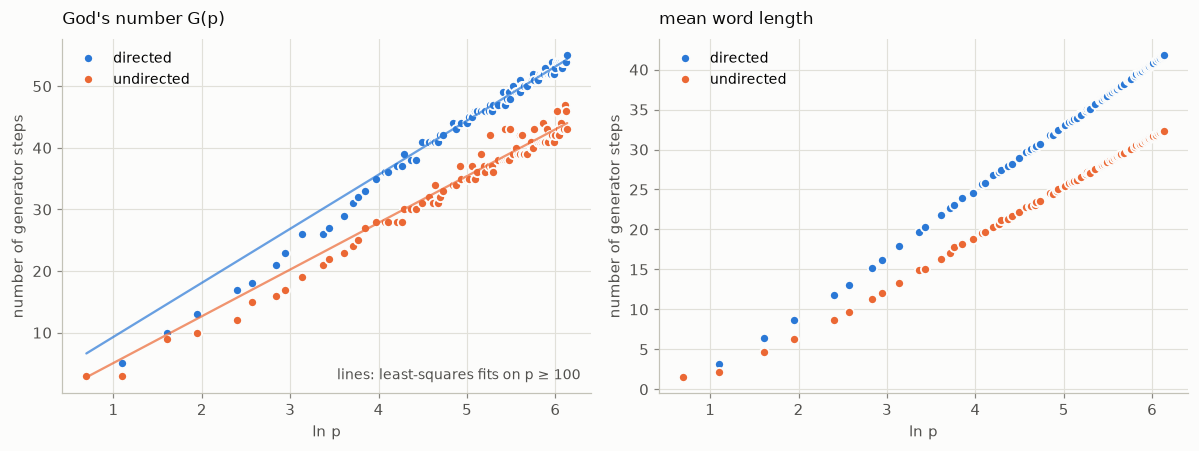

In [7]:
lnp = np.log(table.index.values)
fits = {}
for conv, tag in [("directed", "dir"), ("undirected", "und")]:
    G = table[f"G_{tag}"].values.astype(float)
    for label, mask in [("all p", lnp > 0), ("p >= 100", table.index.values >= 100)]:
        (slope, icpt), cov = np.polyfit(lnp[mask], G[mask], 1, cov=True)
        fits[(conv, label)] = (slope, icpt, math.sqrt(cov[0, 0]))
        print(f"{conv:10s} {label:9s}: G ≈ {slope:5.2f} ln p {icpt:+6.2f}    (slope s.e. {math.sqrt(cov[0,0]):.2f}, "
              f"n = {mask.sum()})")
print()
print("for comparison, the slopes of the lower bounds of §5.4 and §8:")
psi = max(np.roots([1, -1, 0, -1]).real); phi = (1 + 5 ** 0.5) / 2
print(f"  counting:  directed 3/ln2 = {3/math.log(2):.2f},  undirected 3/ln3 = {3/math.log(3):.2f}")
print(f"  growth of SL_2(Z):  directed 3/ln psi = {3/math.log(psi):.2f},  undirected 3/ln phi = {3/math.log(phi):.2f}"
      f"   (psi = {psi:.4f}, phi = {phi:.4f}, see §8)")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True)
for ax, (col, ttl) in zip(axes, [("G", "God's number G(p)"), ("mean", "mean word length")]):
    for conv, tag in [("directed", "dir"), ("undirected", "und")]:
        ax.plot(lnp, table[f"{col}_{tag}"], "o", color=PAL[conv], label=conv, **DOT)
        if col == "G":
            s, i, _ = fits[(conv, "p >= 100")]
            xx = np.linspace(lnp.min(), lnp.max(), 50)
            ax.plot(xx, s * xx + i, color=PAL[conv], alpha=0.7, **LINE)
    style(ax, ttl, "ln p", "number of generator steps")
    ax.legend(loc="upper left")
axes[0].text(0.98, 0.04, "lines: least-squares fits on p ≥ 100", transform=axes[0].transAxes,
             ha="right", color=INK2, fontsize=9)
plt.tight_layout()

### 7.2 How to read the fit

Three things to keep in mind when quoting a "constant $C$" from this data.

1. $G(p)$ is an integer and fluctuates between neighbouring primes — by one or two in the directed
   convention, occasionally by four or more in the undirected one (compare $p = 443$ and $p = 449$ in the
   table) — so the slope of any fit over a range of $\ln p$ of width $\approx 2$ carries an uncertainty of a
   few tenths at best. These jumps are themselves a phenomenon to understand: they come with a change in
   the *type* of farthest element (§10.1).
2. The fitted slope is *not* a lower-bound slope: it sits well above $3/\ln 2$ and $3/\ln 3$, and also above
   the $\mathrm{SL}_2(\mathbb{Z})$-growth slopes of §8, which are the best rigorous lower bounds we have.
3. Whether $\lim G(p)/\ln p$ exists is itself an open question (Section 11). What *is* proven is
   $G(p) = \Theta(\ln p)$: the lower bound from counting and the upper bound from expansion.

The right-hand panel shows that the **mean** length grows with a smaller slope than the maximum: most elements
are much closer to the identity than the farthest ones. Section 9 looks at the whole distribution.

## 8. Results II — the growth of $\mathrm{SL}_2(\mathbb{Z})$ explains most of $G(p)$

### 8.1 The first layers do not depend on $p$

Reduction mod $p$, $\pi : \mathrm{SL}_2(\mathbb{Z}) \to \mathrm{SL}_2(\mathbb{F}_p)$, sends words in $S,T$ to the same words,
so the ball of radius $n$ mod $p$ is $\pi(B_n(\mathbb{Z}))$. Two integer matrices with entries in $[-M, M]$ that
are congruent mod $p$ are equal as soon as $2M < p$. Every entry of a product of $n$ generators is bounded
by the Fibonacci number $F_{n+2}$ (proof in the docstring of `entry_bound`: multiplying by $T^{\pm1}$ adds one
column to the other, multiplying by $S^{\pm1}$ swaps them up to sign). Therefore

$$ 2F_{n+2} < p \ \Longrightarrow\ |L_m(p)| = |L_m(\mathbb{Z})| \text{ for all } m \le n . $$

In words: for $n$ up to about $\log_\varphi p$ the mod-$p$ Cayley graph looks exactly like that of
$\mathrm{SL}_2(\mathbb{Z})$, and the layer sizes are the same for every large prime. In practice the agreement
lasts noticeably longer than this proven radius, because the true maximal entry in $L_n(\mathbb{Z})$ grows
like $1.37^n$ rather than $\varphi^n = 1.618^n$ (the $S$ steps cost a letter without growing the entries).

In [8]:
exact = {c: sl2z_layers(16, c) for c in ["directed", "undirected"]}
print("layers of SL_2(Z) itself, n = 0..16")
for c in exact: print(f"  {c:10s}", exact[c])
print()
print("mod p, for a few primes (identical up to the point where wrap-around begins):")
for p in [31, 101, primes[-1]]:
    for c in ["directed", "undirected"]:
        print(f"  p={p:3d} {c:10s}", DATA[c][p]["layer_sizes"][:17])

def first_deviation(p, conv):
    Lp, Lz = DATA[conv][p]["layer_sizes"], layers_extended(120, conv)
    return next(n for n in range(len(Lp)) if Lp[n] != Lz[n])

dev = pd.DataFrame({"proven injective radius (2F_{n+2} < p)": [injective_radius(p) for p in primes],
                    "first n with |L_n(p)| ≠ |L_n(Z)|, directed": [first_deviation(p, "directed") for p in primes],
                    "first n with |L_n(p)| ≠ |L_n(Z)|, undirected": [first_deviation(p, "undirected") for p in primes]},
                   index=pd.Index(primes, name="p"))
dev.loc[[p for p in primes if p in (11, 31, 61, 101, 151, 211, 307, 401, 499) or p > 500]]

layers of SL_2(Z) itself, n = 0..16
  directed   [1, 2, 4, 7, 11, 17, 25, 37, 54, 79, 116, 170, 249, 365, 535, 784, 1149]
  undirected [1, 4, 11, 20, 32, 52, 84, 136, 220, 356, 576, 932, 1508, 2440, 3948, 6388, 10336]

mod p, for a few primes (identical up to the point where wrap-around begins):
  p= 31 directed   [1, 2, 4, 7, 11, 17, 25, 37, 54, 79, 116, 170, 249, 365, 532, 773, 1105]
  p= 31 undirected [1, 4, 11, 20, 32, 52, 84, 136, 220, 356, 576, 932, 1508, 2440, 3750, 5164, 6052]
  p=101 directed   [1, 2, 4, 7, 11, 17, 25, 37, 54, 79, 116, 170, 249, 365, 535, 784, 1149]
  p=101 undirected [1, 4, 11, 20, 32, 52, 84, 136, 220, 356, 576, 932, 1508, 2440, 3948, 6388, 10336]
  p=461 directed   [1, 2, 4, 7, 11, 17, 25, 37, 54, 79, 116, 170, 249, 365, 535, 784, 1149]
  p=461 undirected [1, 4, 11, 20, 32, 52, 84, 136, 220, 356, 576, 932, 1508, 2440, 3948, 6388, 10336]


,proven injective radius (2F_{n+2} < p),"first n with |L_n(p)| ≠ |L_n(Z)|, directed","first n with |L_n(p)| ≠ |L_n(Z)|, undirected"
p,,,
11,3,10,6
31,5,14,14
61,6,16,16
101,7,18,18
151,8,20,18
211,9,20,20
307,10,22,22
401,10,26,22


### 8.2 Two exact recurrences, and the growth rates $\varphi$ and $\psi$

Enumerating $\mathrm{SL}_2(\mathbb{Z})$ directly (`sl2z_layers`, exact to radius 24 and 30) gives

$$ \text{undirected: } |L_n| = 4F_{n+2}\ (n \ge 3),\qquad\text{so } |L_n| = |L_{n-1}| + |L_{n-2}|,\quad |L_n|^{1/n} \to \varphi = \tfrac{1+\sqrt5}{2} = 1.6180\ldots $$
$$ \text{directed: } |L_n| = |L_{n-1}| + |L_{n-3}|\ (n \ge 8),\qquad |L_n|^{1/n} \to \psi = 1.4655\ldots,\ \text{the real root of } x^3 = x^2 + 1 . $$

These are **observed and machine-verified for the radii enumerated**, not yet proved for all $n$ — a proof should
come from the structure $\mathrm{PSL}_2(\mathbb{Z}) \cong \mathbb{Z}/2 * \mathbb{Z}/3$ (free product, generated by the
images of $S$ and $ST$), whose growth series with respect to any finite generating set is a rational function; see
the open questions. The golden ratio is no surprise: words in $S, T$ are continued fractions in disguise, and
Fibonacci numbers are the worst case for the Euclidean algorithm.

**Why this matters.** Since $|B_n(p)| \le |B_n(\mathbb{Z})|$, God's number satisfies
$$ G(p) \ \ge\ n_{\mathrm{growth}}(p) := \min\{\, n : |B_n(\mathbb{Z})| \ge p^3 - p \,\} \ \approx\ 3\log_\lambda p,\qquad \lambda \in \{\psi, \varphi\}. $$
This replaces the counting slopes $4.33$ and $2.73$ by $3/\ln\psi \approx 7.85$ and $3/\ln\varphi \approx 6.23$.
The comparison below shows that this "free growth" bound accounts for most of $G(p)$; what remains is the
contribution of the wrap-around phase, during which the layers stop growing geometrically.

,G_dir − growth_lb_dir,G_dir / growth_lb_dir,G_und − growth_lb_und,G_und / growth_lb_und
p,,,,
11,3,1.214,2,1.200
31,5,1.227,5,1.294
61,9,1.333,7,1.333
101,10,1.323,7,1.292
151,11,1.324,8,1.296
211,10,1.270,9,1.310
307,11,1.275,10,1.323
401,11,1.262,9,1.273


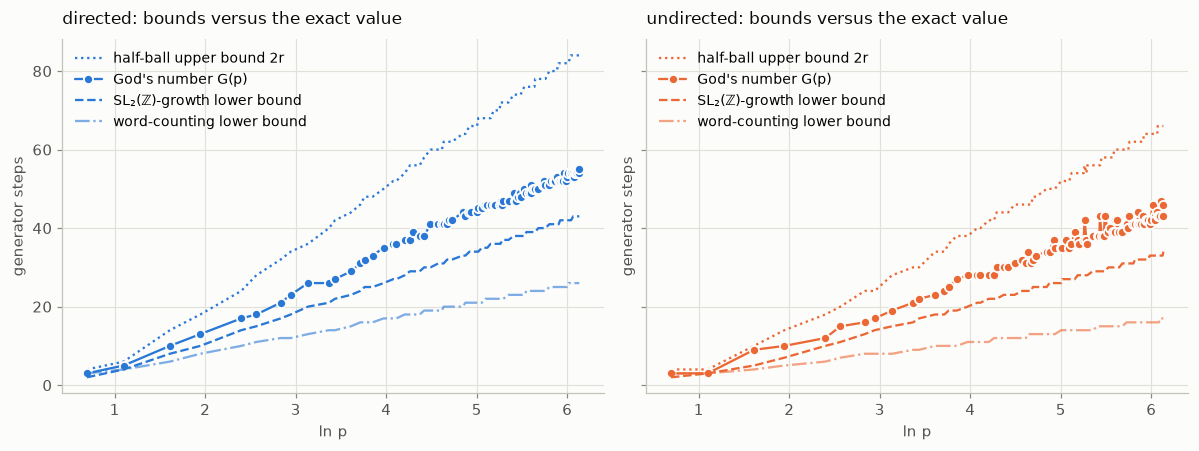

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True, sharey=True)
for ax, (conv, tag) in zip(axes, [("directed", "dir"), ("undirected", "und")]):
    col = PAL[conv]
    ax.plot(lnp, table[f"halfball_ub_{tag}"], ":", color=col, label="half-ball upper bound 2r", **LINE)
    ax.plot(lnp, table[f"G_{tag}"], "o-", color=col, label="God's number G(p)", **LINE, **DOT)
    ax.plot(lnp, table[f"growth_lb_{tag}"], "--", color=col, label="SL₂(ℤ)-growth lower bound", **LINE)
    ax.plot(lnp, table[f"count_lb_{tag}"], "-.", color=col, alpha=0.6, label="word-counting lower bound", **LINE)
    style(ax, f"{conv}: bounds versus the exact value", "ln p", "generator steps")
    ax.legend(loc="upper left")
plt.tight_layout()

excess = pd.DataFrame({
    "G_dir − growth_lb_dir": table["G_dir"] - table["growth_lb_dir"],
    "G_dir / growth_lb_dir": (table["G_dir"] / table["growth_lb_dir"]).round(3),
    "G_und − growth_lb_und": table["G_und"] - table["growth_lb_und"],
    "G_und / growth_lb_und": (table["G_und"] / table["growth_lb_und"]).round(3)})
excess.loc[[p for p in primes if p in (11, 31, 61, 101, 151, 211, 307, 401, 499) or p > 500]]

### 8.3 The profile of one Cayley graph

For a single prime, plotting $|L_n|$ on a logarithmic scale shows the three phases: geometric growth identical to
$\mathrm{SL}_2(\mathbb{Z})$ (dashed), saturation when the layers approach the size of the group, and a thin tail of
"hard" elements that determines $G(p)$. The mean of $\ell$ sits at the peak; the diameter is set by the tail.

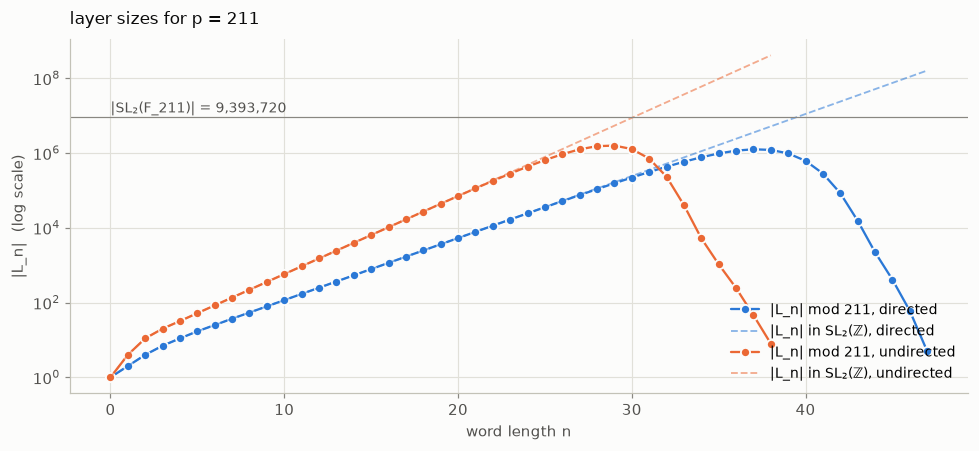

In [10]:
p0 = 211
fig, ax = plt.subplots(figsize=(9, 4.2))
for conv in ["directed", "undirected"]:
    L = DATA[conv][p0]["layer_sizes"]
    ax.plot(range(len(L)), L, "o-", color=PAL[conv], label=f"|L_n| mod {p0}, {conv}", **LINE, **DOT)
    Z = layers_extended(len(L) - 1, conv)
    ax.plot(range(len(Z)), Z, "--", color=PAL[conv], alpha=0.55, label=f"|L_n| in SL₂(ℤ), {conv}", lw=1.2)
ax.axhline(group_order(p0), color=MUTED, lw=0.8)
ax.text(0, group_order(p0) * 1.3, f"|SL₂(F_{p0})| = {group_order(p0):,}", color=INK2, fontsize=9)
ax.set_yscale("log")
style(ax, f"layer sizes for p = {p0}", "word length n", "|L_n|  (log scale)")
ax.legend(loc="lower right")
plt.tight_layout()

## 9. Results III — the distribution of word lengths (reach goal 3)

The proposal asked whether the distribution of $\ell$ converges to a shape as $p \to \infty$. On the raw axis it
cannot: the mean grows like $\ln p$. The natural normalisation is to subtract the mean and look at the spread.
The plots below show the fraction $|L_n|/|G|$ against $n$ (left) and against $n - \text{mean}$ (right) for a
sequence of primes. The right-hand picture is the one to watch: the bulk of the distribution keeps a width of
only a few steps, while the tail toward the diameter slowly lengthens.

mode   mean    sd   G  G − mean  fraction within mean ± 2 fraction in last 3 layers
p   conv                                                                                           
11  directed      13  11.75  2.69  17      5.25                     0.538                  1.18e-01
    undirected    10   8.66  2.13  12      3.34                     0.668                  4.24e-01
31  directed      21  20.29  3.27  27      6.71                     0.492                  5.79e-02
    undirected    16  15.04  2.43  22      6.96                     0.661                  3.97e-03
61  directed      27  25.85  3.44  36     10.15                     0.441                  4.98e-04
    undirected    21  19.64  2.70  28      8.36                     0.558                  6.26e-04
101 directed      31  29.83  3.44  41     11.17                     0.439                  5.73e-05
    undirected    24  22.90  2.79  31      8.10                     0.518                  1.65e-03
151 directed      35  33.09  3.48  45     11.91                     0.474                  2.29e-05
    undirected    27  25.48  2.78  35      9.52                     0.557                  1.13e-04
211 directed      37  35.75  3.47  47     11.25                     0.443                  5.07e-05
    undirected    29  27.53  2.74  38     10.47                     0.563                  3.19e-05
307 directed      40  38.70  3.46  51     12.30                     0.447                  6.57e-06
    undirected    31  29.92  2.77  41     11.08                     0.526                  6.08e-06
401 directed      42  40.65  3.40  53     12.35                     0.457                  4.02e-06
    undirected    33  31.54  2.73  42     10.46                     0.564                  1.22e-05

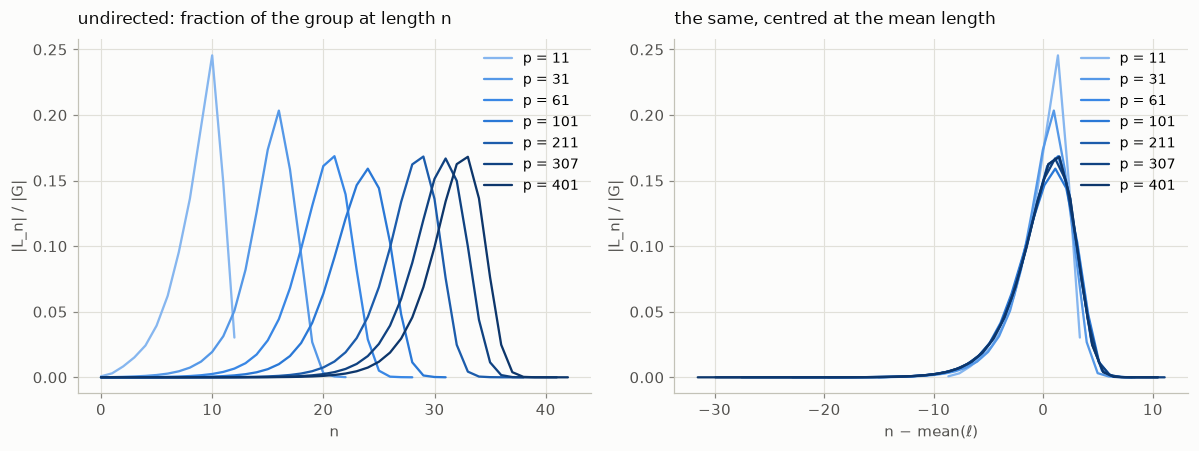

In [11]:
show = [p for p in (11, 31, 61, 101, 211, 307, 401, 499, 1009) if p in DATA["undirected"]]
ramp = [SEQ[i] for i in np.linspace(0, len(SEQ) - 1, len(show)).round().astype(int)]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for p, col in zip(show, ramp):
    L = np.array(DATA["undirected"][p]["layer_sizes"], dtype=float)
    frac = L / L.sum()
    n = np.arange(len(L)); mean = (n * frac).sum()
    axes[0].plot(n, frac, color=col, label=f"p = {p}", **LINE)
    axes[1].plot(n - mean, frac, color=col, label=f"p = {p}", **LINE)
style(axes[0], "undirected: fraction of the group at length n", "n", "|L_n| / |G|")
style(axes[1], "the same, centred at the mean length", "n − mean(ℓ)", "|L_n| / |G|")
axes[0].legend(); axes[1].legend()
plt.tight_layout()

stats = []
for p in primes:
    for conv, tag in [("directed", "dir"), ("undirected", "und")]:
        L = np.array(DATA[conv][p]["layer_sizes"], dtype=float); frac = L / L.sum(); n = np.arange(len(L))
        mean = (n * frac).sum(); sd = math.sqrt(((n - mean) ** 2 * frac).sum())
        stats.append({"p": p, "conv": conv, "mode": int(n[frac.argmax()]), "mean": round(mean, 2), "sd": round(sd, 2),
                      "G": len(L) - 1, "G − mean": round(len(L) - 1 - mean, 2),
                      "fraction within mean ± 2": round(frac[(n >= mean - 2) & (n <= mean + 2)].sum(), 3),
                      "fraction in last 3 layers": f"{frac[-3:].sum():.2e}"})
stats = pd.DataFrame(stats).set_index(["p", "conv"])
stats.loc[[p for p in primes if p in (11, 31, 61, 101, 151, 211, 307, 401, 499) or p > 500]]

Two regularities stand out and deserve a precise statement later: the standard deviation of $\ell$ stops
changing once $p \gtrsim 60$ (about $3.4$ steps in the directed convention, $2.75$ in the undirected one),
while the gap "diameter minus mean" keeps growing, slowly and irregularly, with $\ln p$ — the diameter is
dominated by a vanishing fraction of exceptional elements. This is the same picture as for random regular
graphs (where almost all vertices lie within $O(1)$ of $\log_{k-1} N$), except that here the exceptional
elements are very structured, as the next section shows.

## 10. Results IV — which elements are farthest, and the spectrum

### 10.1 The farthest elements are powers of $T$ (and their relatives)

The BFS records one element of the last layer. Classifying these across all primes:

In [12]:
def classify(m, p):
    a, b, c, d = m
    if a == 1 and d == 1 and c == 0: return "T^k"
    if a == p - 1 and d == p - 1 and c == 0: return "-T^k"
    if b == 0 and c == 0: return "diagonal diag(x, 1/x)"
    if d == 0 and (b * c) % p == p - 1: return "±T^k S  (= [[k, ∓1], [±1, 0]])"
    if a == 0 and (b * c) % p == p - 1: return "±S T^k"
    return "other"

cls = pd.DataFrame({conv: pd.Series([classify(DATA[conv][p]["farthest"], p) for p in primes]).value_counts()
                    for conv in ["directed", "undirected"]}).fillna(0).astype(int)
print(f"type of the recorded farthest element, over {len(primes)} primes:")
cls

type of the recorded farthest element, over 89 primes:


,directed,undirected
-T^k,6,1
T^k,51,46
"diagonal diag(x, 1/x)",4,21
other,25,12
"±T^k S (= [[k, ∓1], [±1, 0]])",3,9


p = 211, directed: G = 47; all 5 elements at that distance:
    [(1, 98, 0, 1), (1, 119, 0, 1), (207, 19, 23, 207), (210, 55, 0, 210), (210, 121, 0, 210)]
p = 211, undirected: G = 38; all 8 elements at that distance:
    [(1, 94, 0, 1), (1, 95, 0, 1), (1, 116, 0, 1), (1, 117, 0, 1), (210, 94, 0, 210), (210, 95, 0, 210), (210, 116, 0, 210), (210, 117, 0, 210)]


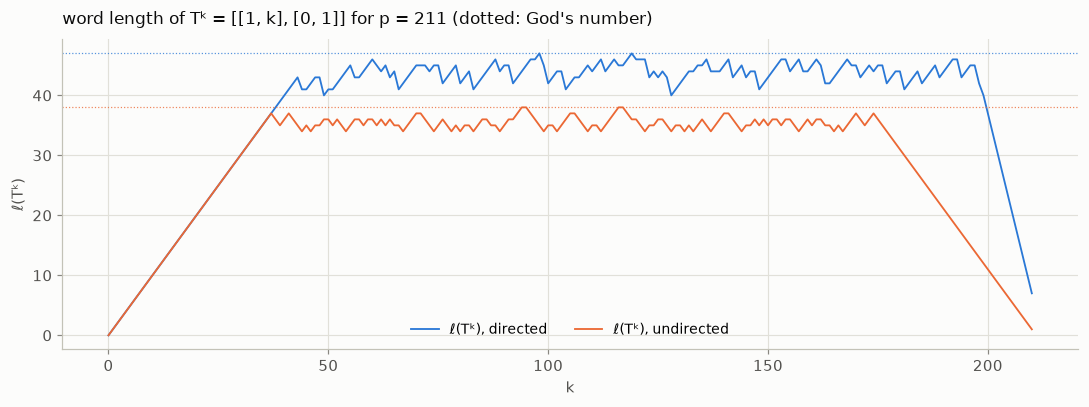

In [13]:
# the whole last layer for one prime, and the length of every power of T
p0 = 211
res = {c: bfs(p0, c, keep_dist=True) for c in ["directed", "undirected"]}
for c, r in res.items():
    far = np.nonzero(r.dist == r.diameter)[0]
    print(f"p = {p0}, {c}: G = {r.diameter}; all {far.size} elements at that distance:")
    print("   ", [decode_scalar(int(i), p0) for i in far])

fig, ax = plt.subplots(figsize=(10, 3.8))
k = np.arange(p0)
for c, r in res.items():
    ell_Tk = r.dist[encode(np.ones(p0, dtype=int), k, np.zeros(p0, dtype=int), np.ones(p0, dtype=int), p0)]
    ax.plot(k, ell_Tk, color=PAL[c], label=f"ℓ(Tᵏ), {c}", lw=1.2)
    ax.axhline(r.diameter, color=PAL[c], lw=0.8, ls=":", alpha=0.8)
style(ax, f"word length of Tᵏ = [[1, k], [0, 1]] for p = {p0} (dotted: God's number)", "k", "ℓ(Tᵏ)")
ax.legend(loc="lower center", ncol=2)
plt.tight_layout()

The picture of $\ell(T^k)$ is the continued-fraction picture of the problem: $T^k$ mod $p$ is reached by any
integer matrix $\equiv T^k \pmod p$, i.e. by any $\begin{pmatrix} 1 + px & k + py\\ pz & 1 + pw\end{pmatrix}$ of
determinant one, and a short word for such a lift corresponds to a short continued-fraction expansion of the
ratio of its entries. Small $k$ and $k$ close to $p$ are cheap ($\ell \le k$ or $\le p - k$ trivially in the
undirected case); the hard $k$ are those for which *every* lift has a long expansion. Larsen's "Navigating the
Cayley graph of $\mathrm{SL}_2(\mathbb{F}_p)$" (IMRN 2003) gives, as far as I recall, an explicit construction of words of
length $O(\log p \log\log p)$ for every element along these lines; whether the maximum of $\ell$ is always attained
at a power of $T$, or a conjugate/negative of one, is open (Section 11).

### 10.2 The spectrum: expander, not Ramanujan

For the undirected 4-regular graphs, `data/spectrum.csv` holds the second-largest adjacency eigenvalue
$\lambda_2$ and the smallest one $\lambda_{\min}$ (ARPACK, `scipy.sparse.linalg.eigsh`) for $p \le 101$.
The Ramanujan threshold is $2\sqrt{3} = 3.4641\ldots$; Chung's bound
$\operatorname{diam} \le \lceil \ln(N-1)/\ln(k/\lambda)\rceil$ with $\lambda = \max(|\lambda_2|, |\lambda_{\min}|)$
is listed for comparison with the true diameter.

,N,lambda2,lambda_min,is_ramanujan,chung_bound,G_und (exact)
p,,,,,,
3,24,2.561553,-3.000000,True,11,3
5,120,3.699315,-3.618034,False,62,9
7,336,3.747595,-3.787759,False,107,10
11,1320,3.823275,-3.877507,False,232,12
13,2184,3.846771,-3.916516,False,365,15
17,4896,3.867088,-3.881189,False,282,16
19,6840,3.886999,-3.913392,False,404,17
23,12144,3.903946,-3.918412,False,457,19
29,24360,3.916227,-3.930671,False,578,21


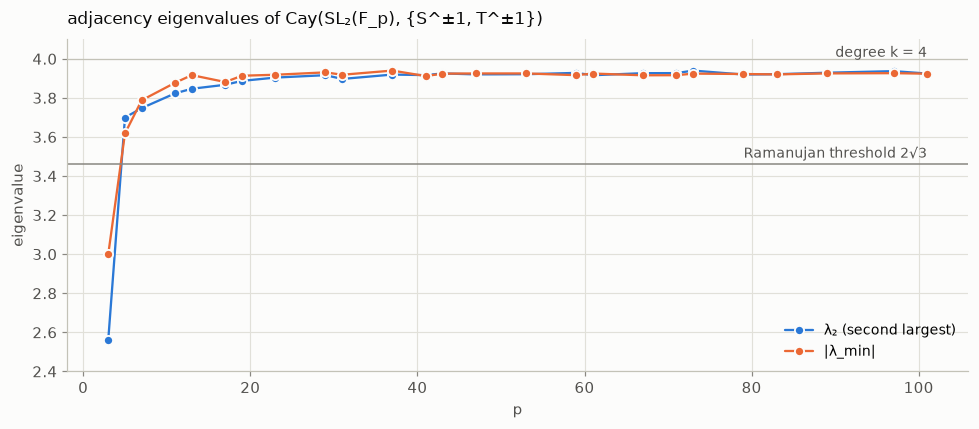

In [14]:
spec = pd.read_csv(ROOT / "data" / "spectrum.csv").set_index("p")
spec["|lambda_min|"] = spec["lambda_min"].abs()
spec["G_und (exact)"] = [DATA["undirected"][p]["diameter"] if p in DATA["undirected"] else None for p in spec.index]
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(spec.index, spec["lambda2"], "o-", color=PAL["directed"], label="λ₂ (second largest)", **LINE, **DOT)
ax.plot(spec.index, spec["|lambda_min|"], "o-", color=PAL["undirected"], label="|λ_min|", **LINE, **DOT)
ax.axhline(2 * math.sqrt(3), color=MUTED, lw=1)
ax.text(spec.index.max(), 2 * math.sqrt(3) + 0.03, "Ramanujan threshold 2√3", ha="right", color=INK2, fontsize=9)
ax.axhline(4, color=AXIS, lw=0.8)
ax.text(spec.index.max(), 4.01, "degree k = 4", ha="right", color=INK2, fontsize=9)
style(ax, "adjacency eigenvalues of Cay(SL₂(F_p), {S^±1, T^±1})", "p", "eigenvalue")
ax.legend(loc="lower right"); ax.set_ylim(2.4, 4.1)
plt.tight_layout()
spec[["N", "lambda2", "lambda_min", "is_ramanujan", "chung_bound", "G_und (exact)"]]

Reading the table: only $p = 3$ (a graph on 24 vertices) is Ramanujan; from $p = 5$ on, $\lambda_2 > 2\sqrt 3$,
and $\lambda_2$ creeps upward with $p$. Selberg's theorem guarantees $\sup_p \lambda_2 < 4$ — this is the expander
property — but the gap $4 - \lambda_2$ is evidently small, which is exactly why spectral diameter bounds such as
Chung's are useless here (hundreds, against true values around 30). The diameter of these graphs is governed by
the fine structure of §8–§10.1, not by the spectral gap alone.

## 11. The goals, re-examined, and open questions

### 11.1 Basic goals — done

| goal | status | where |
|---|---|---|
| 1. arithmetic in $\mathrm{SL}_2(\mathbb{F}_p)$ | done; scalar reference + vectorised | `godsnumber/arith.py`, `godsnumber/index.py` |
| 2. exact BFS, $p$ up to $\approx 100$ | done for all $p \le 500$ and $p \in \{521, 601, 701, 809, 907, 1009\}$, both conventions | `godsnumber/bfs.py`, `data/layers_*.jsonl` |
| 3. table and plot of $G(p)$ vs $\log p$ | done | §7 |
| 4. least-squares estimate of $C$ | done, with the caveats of §7.2 | §7.1 |

### 11.2 Reach goals — re-assessed

1. **An RL solver for $p > 500$ "where BFS is intractable".** The premise is false by a wide margin: a
   vectorised BFS does $p \approx 1000$ ($10^9$ elements) in minutes on a laptop, and a C implementation with two
   bits per element would reach $p \approx 3000$ ($N \approx 2.7\cdot 10^{10}$, 7 GB). Beyond that, memory — not
   time — is the obstacle, and a learned solver can be useful there *for finding words*, not for diameters.
2. **Solver lengths as a "practical diameter".** A word found for an element $\gamma$ proves $\ell(\gamma) \le$ its
   length — an upper bound for *that* element. The diameter is a maximum over all elements, so solver lengths bound
   it from neither side unless every element is covered. Rigorous substitutes: the half-ball lemma (§5.5) for upper
   bounds; the $\mathrm{SL}_2(\mathbb{Z})$-growth bound (§8.2) for lower bounds; and, for candidate farthest elements,
   §10.1 suggests testing $\ell(T^k)$ only.
3. **Distribution of lengths.** Partly done (§9); the right normalisation is $n - \text{mean}$, and the bulk width
   appears to stay bounded while the tail grows.
4. **Generator sensitivity.** Started below: the same computation with $\{T, U\}$ and $\{S, ST\}$ in place of $\{S, T\}$.

In [15]:
ST = (0, -1, 1, 1)                      # S T = [[0, -1], [1, 1]], of order 6
bases = {"{S, T}": (S, T), "{T, U}": (T, U), "{S, ST}": (S, ST)}
rows = []
for p in [p for p in primes if p <= 151]:
    row = {"p": p}
    for name, base in bases.items():
        for conv, tag in [("directed", "dir"), ("undirected", "und")]:
            gens = generators(p, conv, base=tuple(reduce_mod(g, p) for g in base))
            row[f"{name} {tag}"] = bfs(p, conv, gens=gens).diameter
    rows.append(row)
gensens = pd.DataFrame(rows).set_index("p")
print("God's number for three generating pairs (dir = no inverses, und = with inverses)")
gensens

God's number for three generating pairs (dir = no inverses, und = with inverses)


,"{S, T} dir","{S, T} und","{T, U} dir","{T, U} und","{S, ST} dir","{S, ST} und"
p,,,,,,
2,3,3,3,3,2,2
3,5,3,5,4,5,3
5,10,9,8,6,13,10
7,13,10,10,7,17,12
11,17,12,13,10,22,17
13,18,15,14,10,23,19
17,21,16,17,12,27,21
19,23,17,17,13,30,24
23,26,19,17,14,34,26


In [16]:
# directed word lengths of the inverses of the generators (used in open question 6)
for p in [101, 211]:
    r = bfs(p, "directed", keep_dist=True)
    s, t = reduce_mod(S, p), reduce_mod(T, p)
    print(f"p = {p}: ℓ_dir(S^-1) = {r.dist[encode_scalar(inverse(s, p), p)]},  "
          f"ℓ_dir(T^-1) = {r.dist[encode_scalar(inverse(t, p), p)]},  ℓ_dir(-I) = {r.dist[encode_scalar((p-1, 0, 0, p-1), p)]}")
p = 211
assert mat_pow(reduce_mod(S, p), 3, p) == inverse(reduce_mod(S, p), p)          # S^-1 = S^3
w = matmul(mat_pow(reduce_mod(S, p), 3, p), matmul(reduce_mod(T, p), matmul(reduce_mod(S, p), matmul(reduce_mod(T, p), reduce_mod(S, p), p), p), p), p)
assert w == inverse(reduce_mod(T, p), p)                                         # T^-1 = S^3 T S T S  (7 letters)
print("checked: T^-1 = S^3 T S T S, a directed word of length 7")

p = 101: ℓ_dir(S^-1) = 3,  ℓ_dir(T^-1) = 7,  ℓ_dir(-I) = 2


p = 211: ℓ_dir(S^-1) = 3,  ℓ_dir(T^-1) = 7,  ℓ_dir(-I) = 2
checked: T^-1 = S^3 T S T S, a directed word of length 7


### 11.3 Open questions (precise formulations)

1. **Prove the recurrences of §8.2.** Show that the spheres of $\mathrm{SL}_2(\mathbb{Z})$ satisfy
   $|L_n| = 4F_{n+2}$ ($n \ge 3$) for $\{S^{\pm1}, T^{\pm1}\}$ and $|L_n| = |L_{n-1}| + |L_{n-3}|$ ($n \ge 8$) for
   $\{S, T\}$. Route: normal forms in $\mathrm{PSL}_2(\mathbb{Z}) = \langle s\rangle * \langle u\rangle$, $s = \bar S$,
   $u = \overline{ST}$, keeping track of the central element $-I = S^2$.
2. **Does $\lim_{p\to\infty} G(p)/\ln p$ exist?** The data of §7 are consistent with a limit but cannot establish
   one; even $\limsup$ vs $\liminf$ along subsequences of primes is unknown. Related: is $G(p) - n_{\mathrm{growth}}(p)$
   bounded by a constant times $\ln p$ with a small constant, or by something smaller (e.g. $\ln\ln p$)?
3. **Is the maximum always attained on $\{\pm T^k\} \cup \{\pm T^k S\} \cup \{\text{diagonal}\}$?** In the data the
   recorded farthest element is almost always of one of these forms (§10.1). A proof would reduce $G(p)$ to a
   one-parameter problem: $G(p) = \max_k \ell(T^k)$ or a close relative.
4. **An exact formula for $\ell(T^k)$ in terms of continued fractions of lifts.** This would make $G(p)$
   computable for primes far beyond the reach of any BFS, by number theory instead of search.
5. **Sharper spectral statements.** Does $\lambda_2(p)$ converge, and to what? How does $4 - \lambda_2(p)$ compare with
   the bound implied by Selberg's $3/16$?
6. **Directed vs undirected.** Replacing each $S^{-1}$ by $S^3$ and each $T^{-1}$ by its shortest directed
   word gives $\ell_{\mathrm{dir}}(\gamma) \le 7\,\ell_{\mathrm{undir}}(\gamma)$ (the cell above shows
   $\ell_{\mathrm{dir}}(S^{-1}) = 3$ and $\ell_{\mathrm{dir}}(T^{-1}) = 7$, the latter from
   $(ST)^3 = -I = S^2$, which gives $T^{-1} = S^3\,T S T S$ after cancelling). The observed ratio of diameters
   in §7 is only about $1.15$–$1.35$. Is there an inequality $\ell_{\mathrm{dir}} \le c\,\ell_{\mathrm{undir}} + O(1)$
   with $c$ close to the observed ratio, and does $G_{\mathrm{dir}}(p)/G_{\mathrm{undir}}(p)$ converge?

### 11.4 Corrections to the proposal text, collected

* $\mathbb{Z}_p \to \mathbb{Z}/p\mathbb{Z}$ or $\mathbb{F}_p$; "$\mathrm{SL}_2(\mathbb{Z})$ and its diameter" $\to$ the diameters of the finite quotients.
* $S$ and $T$ should be defined; the convention (inverses or not) must be fixed, since the numbers differ.
* "$G = O(\log p)$ is known" is true but follows from Selberg (expansion), not from Helfgott, whose theorem gives
  $(\log p)^{O(1)}$ for *every* generating set.
* "These will be Ramanujan graphs": false for $p \ge 5$ (§10.2); "expander family" is the correct claim.
* Reach goal 2's logic: solver lengths do not bound the diameter (§11.2).
* The BibTeX title field should be braced to keep the capitals in "SL\_2(Z/pZ)"; the Lubotzky–Phillips–Sarnak entry
  lacks the journal (Combinatorica 8 (1988), 261–277).

## 12. References

* H. A. Helfgott, *Growth and generation in $\mathrm{SL}_2(\mathbb{Z}/p\mathbb{Z})$*, Ann. of Math. (2) 167 (2008), 601–623. arXiv:math/0509024.
* A. Lubotzky, R. Phillips, P. Sarnak, *Ramanujan graphs*, Combinatorica 8 (1988), 261–277.
* A. Selberg, *On the estimation of Fourier coefficients of modular forms*, Proc. Sympos. Pure Math. VIII (1965), 1–15.
* A. Lubotzky, *Discrete groups, expanding graphs and invariant measures*, Progress in Math. 125, Birkhäuser, 1994.
* G. Davidoff, P. Sarnak, A. Valette, *Elementary number theory, group theory, and Ramanujan graphs*, LMS Student Texts 55, CUP, 2003.
* J. Bourgain, A. Gamburd, *Uniform expansion bounds for Cayley graphs of $\mathrm{SL}_2(\mathbb{F}_p)$*, Ann. of Math. (2) 167 (2008), 625–642.
* E. Breuillard, B. Green, T. Tao, *Approximate subgroups of linear groups*, GAFA 21 (2011), 774–819.
* L. Pyber, E. Szabó, *Growth in finite simple groups of Lie type*, J. Amer. Math. Soc. 29 (2016), 95–146.
* M. Larsen, *Navigating the Cayley graph of $\mathrm{SL}_2(\mathbb{F}_p)$*, Int. Math. Res. Not. 2003, no. 27, 1465–1471.
* F. R. K. Chung, *Diameters and eigenvalues*, J. Amer. Math. Soc. 2 (1989), 187–196.
* T. Rokicki, H. Kociemba, M. Davidson, J. Dethridge, *The diameter of the Rubik's cube group is twenty*, SIAM J. Discrete Math. 27 (2013), 1082–1105.
* A. Chervov et al., *CayleyPy RL: Pathfinding and reinforcement learning on Cayley graphs*, arXiv:2502.18663 (2025).

## Appendix — reproducing everything

```
pip install -r requirements.txt
python -m pytest tests                                   # 49 checks, ~10 s
python scripts/compute_table.py --pmax 500 --convention directed   --out data/layers_directed.jsonl
python scripts/compute_table.py --pmax 500 --convention undirected --out data/layers_undirected.jsonl
python scripts/compute_table.py --primes 521 601 701 809 907 1009 --convention directed   --out data/layers_directed.jsonl
python scripts/compute_table.py --primes 521 601 701 809 907 1009 --convention undirected --out data/layers_undirected.jsonl
python scripts/compute_spectrum.py --pmax 101 --out data/spectrum.csv
python notebooks/build_notebook.py                       # regenerates and re-executes this notebook
```
Run times on four cores: all primes to 500 take about 20 minutes per convention; $p = 1009$ takes a few minutes
and 1 GB per run. File formats: one JSON object per line with keys `p, convention, order, diameter, layer_sizes,
farthest, seconds`; the spectrum file is a CSV with a header.

In [17]:
print("executed on", time.strftime("%Y-%m-%d %H:%M"), "with numpy", np.__version__, "| primes in the tables:", len(primes),
      "| largest p:", primes[-1])

executed on 2026-10-25 23:50 with numpy 2.4.6 | primes in the tables: 89 | largest p: 461
